# LAB 11 - Human–AI Judgment Bias
### Decision Tree · Random Forest · XGBoost

**Disciplina:** Inteligência Artificial - PPGI/UNIRIO (2026.2)  
**Base:** `Exp2.csv` - Glickman & Sharot (Nature Human Behaviour, 2025)

**Questão:** o histórico de julgamentos e interações anteriores permite prever melhor os desvios das novas estimativas humanas?

**Nota crítica:** prever um desvio numérico não comprova viés cognitivo individual nem mecanismo causal.

## 1. Ambiente e importação

Este notebook pode ser aberto tanto da pasta raiz quanto da pasta `notebooks/`. O CSV foi incluído no pacote, mas é ignorado no Git por padrão. Instale `requirements.txt` antes de executar.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'data' / 'Exp2.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'Exp2.csv').exists(), 'Abra o notebook no laboratório ou copie data/Exp2.csv.'
sys.path.insert(0, str(ROOT))

from src.data import (load_data, audit_data, make_features, STATIC_FEATURES,
                      HISTORY_FEATURES, CONDITIONS, TARGET)
from src.models import participant_split, features_for, make_pipeline, scores

print('Raiz:', ROOT)

Raiz: /home/andre-cataldo/projects/ai-ppgi/labs/aula-11-random-forest


## 2. Auditoria do CSV

A unidade de observação é uma **tentativa**, não uma pessoa independente. `collaboration` é ausente nas 30 tentativas baseline por participante, o que decorre do desenho experimental.

In [2]:
raw = load_data(ROOT / 'data' / 'Exp2.csv')
audit = audit_data(raw, strict=True)
print(json.dumps(audit, ensure_ascii=False, indent=2))
display(raw.head(5))
display(raw.isna().sum().to_frame('Valores ausentes'))

{
  "rows": 14400,
  "participants": 120,
  "columns": 11,
  "trials_per_participant": {
    "min": 120,
    "max": 120
  },
  "condition_counts": {
    "0": 3600,
    "1": 3600,
    "2": 3600,
    "3": 3600
  },
  "missing_by_column": {
    "subject": 0,
    "evidence": 0,
    "response": 0,
    "responseAI": 0,
    "confidence": 0,
    "collaboration": 3600,
    "condition": 0,
    "order": 0,
    "perceivedInfluenceA": 0,
    "perceivedInfluenceB": 0,
    "perceivedInfluenceN": 0
  },
  "duplicated_exact_rows": 1,
  "order_subject_counts": {
    "1": 40,
    "2": 40,
    "3": 40
  },
  "sequence_patterns": {
    "((0, 30), (1, 30), (2, 30), (3, 30))": 40,
    "((0, 30), (2, 30), (3, 30), (1, 30))": 40,
    "((0, 30), (3, 30), (1, 30), (2, 30))": 40
  },
  "strict_validation": true
}


,subject,evidence,response,responseAI,confidence,collaboration,condition,order,perceivedInfluenceA,perceivedInfluenceB,perceivedInfluenceN
0,1,56,49.594989,56,0.332093,NaN,0,1,5.031049,5.031049,5.964199
1,1,32,75.238123,31,0.504282,NaN,0,1,5.031049,5.031049,5.964199
2,1,62,26.729079,63,0.332093,NaN,0,1,5.031049,5.031049,5.964199
3,1,28,28.302843,28,0.673693,NaN,0,1,5.031049,5.031049,5.964199
4,1,22,33.579593,21,0.662584,NaN,0,1,5.031049,5.031049,5.964199


,Valores ausentes
subject,0
evidence,0
response,0
responseAI,0
confidence,0
collaboration,3600
condition,0
order,0
perceivedInfluenceA,0
perceivedInfluenceB,0


## 3. Exploração das quatro condições

Os códigos são: `0` sem IA, `1` IA precisa, `2` IA enviesada, `3` IA ruidosa. Abaixo, o **erro assinado** positivo é uma sobrestimação da proporção de pontos; o erro absoluto mede distância da evidência real.

,registros,participantes,desvio_medio,mae_humano
Sem IA,3600,120,0.620,15.030
IA precisa,3600,120,1.268,13.483
IA enviesada,3600,120,2.655,14.736
IA ruidosa,3600,120,1.155,14.358


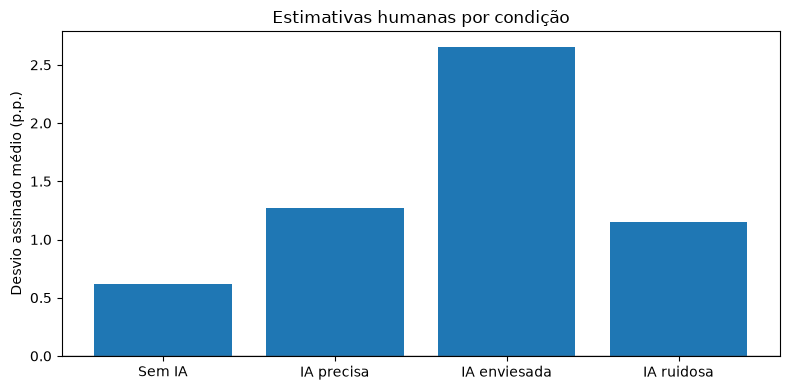

In [3]:
frame = make_features(raw)
by_condition = frame.groupby('condition').agg(
    registros=('subject', 'size'), participantes=('subject', 'nunique'),
    desvio_medio=(TARGET, 'mean'), mae_humano=('absolute_error', 'mean'))
by_condition.index = [CONDITIONS[c] for c in by_condition.index]
display(by_condition.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_condition.index, by_condition['desvio_medio'])
ax.axhline(0, color='0.3', linewidth=1)
ax.set_ylabel('Desvio assinado médio (p.p.)')
ax.set_title('Estimativas humanas por condição')
plt.tight_layout();plt.show()

## 4. Tempo experimental e vazamento de informação

**Sequência da tentativa t:** estímulo → estimativa humana (`response_t`) → confiança → ponderação → **revelação** de `responseAI_t`. Assim, a resposta da IA na tentativa *t* não pode explicar diretamente a estimativa humana **anterior** na mesma tentativa.

As features históricas são construídas com `shift(1)` **por participante**. O uso do histórico observado de uma nova pessoa antes do instante *t* configura previsão **online**, não *cold start* estrito.

In [4]:
participant = frame[frame.subject == 1]
show = ['trial_index','condition','evidence','response','responseAI',
        'shown_ai_bias','signed_error','lag1_error','lag1_shown_ai_bias']
display(pd.concat([participant.iloc[28:33], participant.iloc[58:63]])[show])
print('Contexto:', STATIC_FEATURES)
print('Histórico adicional:', HISTORY_FEATURES)
assert set(features_for('historico')).isdisjoint(
    {'response', 'responseAI', 'confidence', 'collaboration', 'subject'})

,trial_index,condition,evidence,response,responseAI,shown_ai_bias,signed_error,lag1_error,lag1_shown_ai_bias
28,29,0,48,49.872714,49,NaN,1.872714,-4.682737,NaN
29,30,0,40,30.524636,40,NaN,-9.475364,1.872714,NaN
30,31,1,52,49.687560,53,1.0,-2.312440,-9.475364,NaN
31,32,1,30,55.982628,29,-1.0,25.982628,-2.312440,1.0
32,33,1,42,33.209302,43,1.0,-8.790698,25.982628,-1.0
58,59,1,36,64.592053,36,0.0,28.592053,-7.145611,-1.0
59,60,1,28,43.022195,28,0.0,15.022195,28.592053,0.0
60,61,2,36,50.335582,77,41.0,14.335582,15.022195,0.0
61,62,2,6,25.988486,32,26.0,19.988486,14.335582,41.0
62,63,2,68,57.186095,96,28.0,-10.813905,19.988486,26.0


Contexto: ['evidence', 'condition', 'order', 'trial_index', 'trial_in_block']
Histórico adicional: ['lag1_error', 'rolling5_prior_error', 'prior_mean_error', 'rolling5_prior_absolute_error', 'lag1_confidence', 'rolling5_prior_confidence', 'lag1_shown_ai_bias', 'rolling5_prior_shown_ai_bias', 'prior_mean_shown_ai_bias', 'rolling5_prior_collaboration']


## 5. Divisão por participante (group holdout)

O mesmo participante **nunca** aparece simultaneamente em treino e teste. A validação cruzada completa ocorre no script principal, também agrupada por pessoa. Para estudo didático do notebook, abaixo construímos uma versão comparativa de RF com os mesmos hiperparâmetros.

In [5]:
train_idx, test_idx = participant_split(frame, seed=42, test_size=.25)
train, test = frame.iloc[train_idx].copy(), frame.iloc[test_idx].copy()
print('Pessoas no treino:', train.subject.nunique())
print('Pessoas no teste:', test.subject.nunique())
print('Interseção:', set(train.subject) & set(test.subject))
assert set(train.subject).isdisjoint(test.subject)

Pessoas no treino: 90
Pessoas no teste: 30
Interseção: set()


## 6. Baseline e comparação didática de Random Forest

O baseline prevê que o participante acertará a proporção do estímulo (desvio **zero**). Treinamos RF no conjunto de treino sob duas condições: `contexto` versus `historico`. Isso demonstra a ablação principal sem repetir todo o pipeline de avaliação cruzada do script.

In [6]:
predictions = {'Zero': np.zeros(len(test))}
for scenario in ['contexto','historico']:
    columns = features_for(scenario)
    model = make_pipeline('Random Forest', columns, seed=42, quick=True)
    model.fit(train[columns], train[TARGET])
    predictions[f'RF_{scenario}'] = model.predict(test[columns])
for name, values in predictions.items():
    print(name, {k: round(v,3) for k,v in scores(test[TARGET],values).items()})

Zero {'MAE': 14.176, 'RMSE': 19.224, 'R2': -0.002, 'bias_residual': -0.779}
RF_contexto {'MAE': 13.604, 'RMSE': 17.715, 'R2': 0.149, 'bias_residual': 0.743}
RF_historico {'MAE': 12.641, 'RMSE': 16.972, 'R2': 0.219, 'bias_residual': 0.703}


## 7. Execução completa: DT, RF e XGBoost

Os resultados completos são gerados pelo terminal: `python run_lab.py`. Caso ainda não estejam disponíveis, esta célula os produz usando a configuração **completa**, com validação cruzada agrupada nos participantes do treino.

In [7]:
results_dir = ROOT / 'results'
metrics_path = results_dir / 'METRICAS_MODELOS.csv'
if not metrics_path.exists():
    from src.experiment import execute
    execute(ROOT / 'data' / 'Exp2.csv', results_dir, quick=False, cv=True, seed=42)
metrics = pd.read_csv(metrics_path)
show = ['tipo','modelo','cenario','MAE','RMSE','R2','cv_mae_mean','late_block_MAE']
display(metrics[show].round(3))

,tipo,modelo,cenario,MAE,RMSE,R2,cv_mae_mean,late_block_MAE
0,baseline,Zero,referencia,14.176,19.224,-0.002,NaN,13.171
1,baseline,Média do treino,referencia,14.301,19.227,-0.002,NaN,13.197
2,baseline,Persistência anterior,referencia,19.144,26.021,-0.835,NaN,17.273
3,modelo,Decision Tree,contexto,13.604,17.680,0.153,14.181,12.835
4,modelo,Decision Tree,historico,13.026,17.268,0.192,13.845,12.240
5,modelo,Random Forest,contexto,13.600,17.705,0.150,14.230,12.828
6,modelo,Random Forest,historico,12.608,16.918,0.224,13.241,11.824
7,modelo,XGBoost,contexto,13.535,17.618,0.159,14.116,12.819
8,modelo,XGBoost,historico,12.674,16.870,0.229,13.342,11.842


## 8. Desempenho por condição

Os efeitos preditivos podem variar entre contexto sem IA, IA precisa, enviesada e ruidosa. A tabela abaixo avalia os mesmos **participantes não vistos** do conjunto de teste, mas separa suas tentativas por condição.

In [8]:
condition_scores = pd.read_csv(results_dir / 'METRICAS_POR_CONDICAO.csv')
selection = condition_scores[
    (condition_scores.modelo.isin(['Random Forest','XGBoost'])) &
    (condition_scores.cenario.isin(['contexto','historico']))
]
selection = selection.pivot_table(index=['modelo','condition'], columns='cenario',values='MAE')
selection['ganho'] = selection['contexto'] - selection['historico']
display(selection.round(3))

cenario                  contexto  historico  ganho
modelo        condition                            
Random Forest 0            14.342     13.654  0.688
              1            12.729     11.609  1.120
              2            13.797     12.611  1.186
              3            13.531     12.560  0.971
XGBoost       0            14.217     13.742  0.475
              1            12.674     11.751  0.923
              2            13.734     12.536  1.198
              3            13.516     12.668  0.848

## 9. Incerteza de comparação por pessoa

O intervalo foi calculado reamostrando **participantes inteiros**, e não tentando tratar 3.600 linhas do teste como eventos independentes. Isso descreve a incerteza da diferença de MAE **para estes modelos treinados**.

,modelo,delta_mae,ci95_low,ci95_high,participantes
0,Decision Tree,0.578,0.129,1.056,30
1,Random Forest,0.991,0.541,1.490,30
2,XGBoost,0.861,0.323,1.433,30


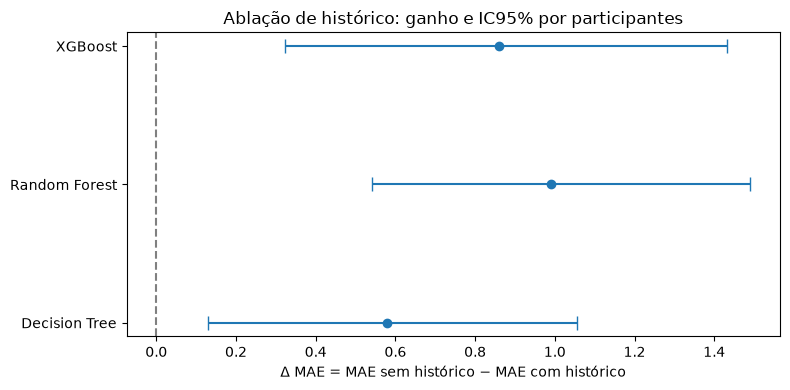

In [9]:
effects = pd.read_csv(results_dir / 'INCERTEZA_HISTORICO.csv')
display(effects.round(3))
fig,ax=plt.subplots(figsize=(8,4))
ax.errorbar(effects.delta_mae, effects.modelo,
            xerr=[effects.delta_mae-effects.ci95_low,
                  effects.ci95_high-effects.delta_mae],
            fmt='o',capsize=5)
ax.axvline(0,linestyle='--',color='0.5')
ax.set_xlabel('Δ MAE = MAE sem histórico − MAE com histórico')
ax.set_title('Ablação de histórico: ganho e IC95% por participantes')
plt.tight_layout();plt.show()

## 10. Gráficos da execução principal

**01_vies_por_condicao.png**

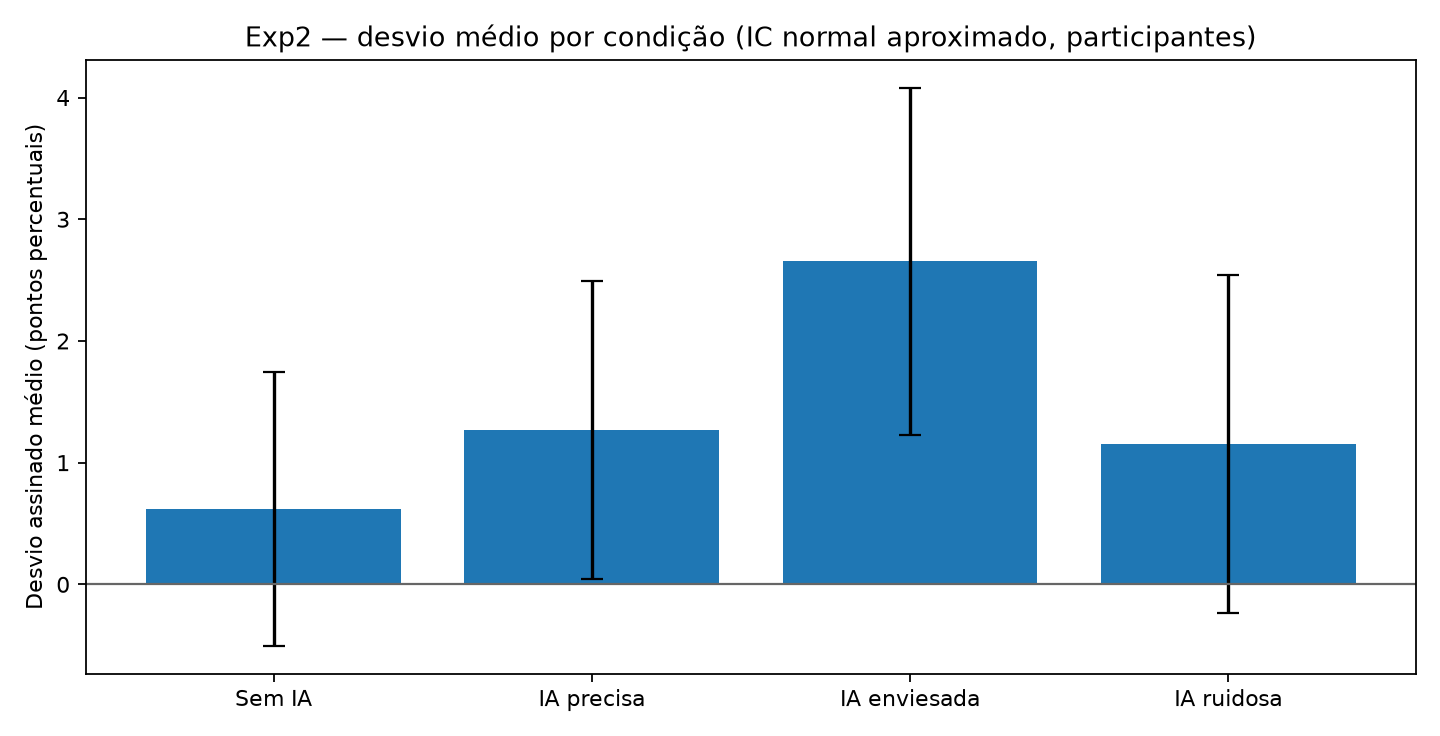

**02_mae_modelos.png**

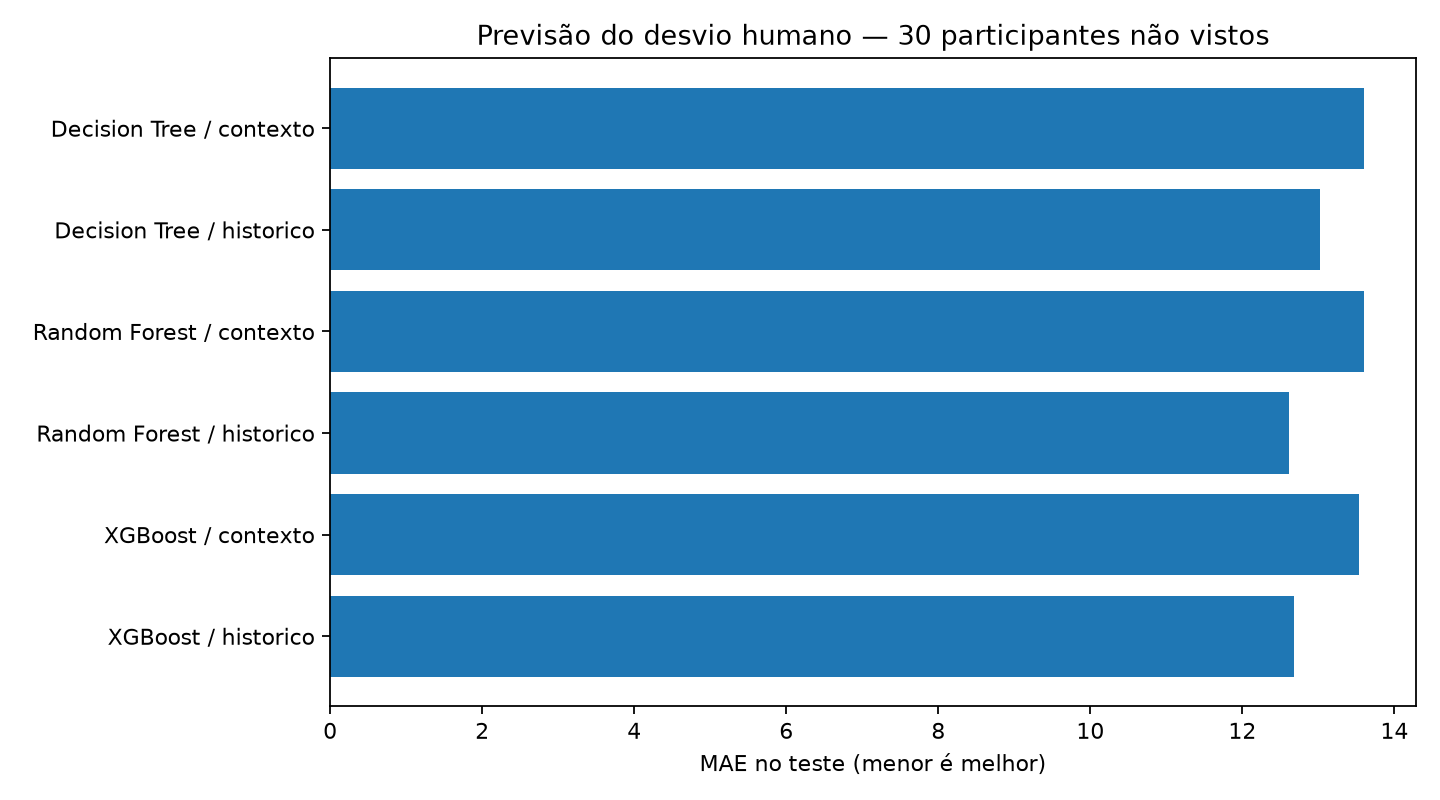

**04_real_vs_previsto.png**

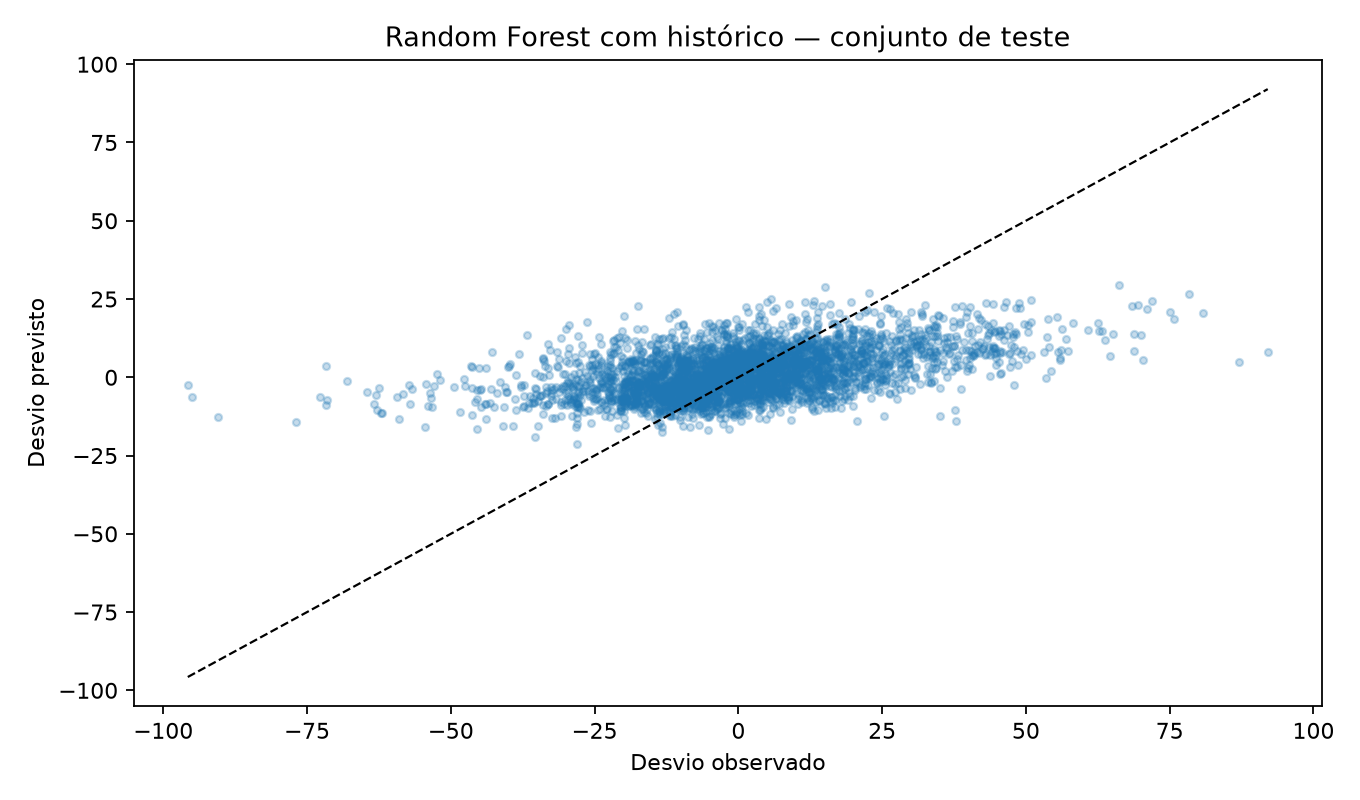

In [10]:
from IPython.display import Image
for fn in ['01_vies_por_condicao.png','02_mae_modelos.png','04_real_vs_previsto.png']:
    display(Markdown(f'**{fn}**'))
    display(Image(filename=str(results_dir/fn)))

## 11. Discussão crítica (responda com suas palavras)

1. Por que não é permitido usar `responseAI_t` para prever `response_t` no mesmo trial?
2. Como a validação por participante difere de uma divisão aleatória de linhas?
3. O histórico melhora a predição porque a IA causa viés ou porque os julgamentos são temporalmente autocorrelacionados? Que novo experimento separaria as explicações?
4. Qual é a diferença entre `response - evidence` e uma demonstração de viés sistemático?
5. Por que Random Forest poderia superar XGBoost em MAE, mas perder em R²?
6. O que as limitações de importância de atributos apontadas por Strobl et al. sugerem sobre interpretações de nossos modelos?

**Extensão sugerida:** adicionar um terceiro cenário usando apenas **histórico de conselho revelado** e comparar com um quarto usando apenas **histórico comportamental humano**, sob a mesma divisão e métricas.

## Referências

- Glickman & Sharot (2025), *Nature Human Behaviour*: https://doi.org/10.1038/s41562-024-02077-2.
- Strobl et al. (2007), *BMC Bioinformatics*.
- Chen & Guestrin (2016), *XGBoost: A Scalable Tree Boosting System*.

**Reprodutibilidade:** use `python run_lab.py` e `python -m pytest -v` para validar o pacote completo.